# BÀI 2 (TRANG 32 - BÀI TẬP THÊM): TÍNH GIÁ TRỊ F-MEASURE CỦA CÁC BÀI TẬP CƠ BẢN
- **Sinh viên thực hiện:** Dương Đại Phát
- **MSSV:** 6451071058
- **Công thức:**
$$F\text{-measure} = \frac{2 \times \text{precision} \times \text{recall}}{\text{precision} + \text{recall}}$$

In [1]:
print("Dương Đại Phát - 6451071058")
%matplotlib inline
import math
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import metrics

def calc_f_measure(precision, recall):
    if precision + recall == 0:
        return 0.0
    return 2 * precision * recall / (precision + recall)

# Cài đặt lại thuật toán ID3 / CART (chia đa nhánh theo thuộc tính rời rạc) và Naive Bayes (Laplace)
def entropy(labels):
    n = len(labels)
    return -sum((c / n) * math.log2(c / n) for c in Counter(labels).values())

def gini(labels):
    n = len(labels)
    return 1 - sum((c / n) ** 2 for c in Counter(labels).values())

def build_tree(rows, feat_names, criterion='gini'):
    labels = [r[-1] for r in rows]
    if len(set(labels)) == 1:
        return labels[0]
    if not feat_names:
        return Counter(labels).most_common(1)[0][0]
    n = len(rows)
    best_idx, best_score = None, (-1 if criterion == 'entropy' else 999)
    base_ent = entropy(labels)
    for idx in range(len(feat_names)):
        groups = defaultdict(list)
        for r in rows:
            groups[r[idx]].append(r)
        if criterion == 'entropy':
            gain = base_ent - sum((len(g) / n) * entropy([x[-1] for x in g]) for g in groups.values())
            if gain > best_score:
                best_score, best_idx = gain, idx
        else:
            g_idx = sum((len(g) / n) * gini([x[-1] for x in g]) for g in groups.values())
            if g_idx < best_score:
                best_score, best_idx = g_idx, idx
    feat = feat_names[best_idx]
    tree_node = {feat: {'_default': Counter(labels).most_common(1)[0][0]}}
    groups = defaultdict(list)
    for r in rows:
        groups[r[best_idx]].append(r[:best_idx] + r[best_idx + 1:])
    rem_feats = feat_names[:best_idx] + feat_names[best_idx + 1:]
    for val, g in groups.items():
        tree_node[feat][val] = build_tree(g, rem_feats, criterion)
    return tree_node

def predict_tree(tree_node, feat_names, sample):
    if not isinstance(tree_node, dict):
        return tree_node
    feat = next(iter(tree_node))
    idx = feat_names.index(feat)
    val = sample[idx]
    sub = tree_node[feat].get(val, tree_node[feat]['_default'])
    return predict_tree(sub, feat_names, sample)

def nb_predict(train_rows, sample):
    classes = sorted(set(r[-1] for r in train_rows))
    n = len(train_rows)
    n_classes = len(classes)
    num_feats = len(train_rows[0]) - 1
    feat_vals = [set(r[i] for r in train_rows) for i in range(num_feats)]
    scores = {}
    for c in classes:
        c_rows = [r for r in train_rows if r[-1] == c]
        nc = len(c_rows)
        p = (nc + 1) / (n + n_classes)
        for i in range(num_feats):
            count_xi = sum(1 for r in c_rows if r[i] == sample[i])
            p *= (count_xi + 1) / (nc + len(feat_vals[i]))
        scores[c] = p
    return max(scores, key=scores.get)

Dương Đại Phát - 6451071058


## 1. Bài tập cơ bản 1 (Mục III.1 - Trang 1-15): Đánh giá rủi ro hồ sơ vay tín dụng

In [2]:
print("Dương Đại Phát - 6451071058")
credit_train = [
    ('Thấp', 'Vận tải', 'Độc thân', 'Rồi', 'Rủi ro cao'),
    ('Thấp', 'Vận tải', 'Độc thân', 'Chưa', 'Rủi ro cao'),
    ('Cao', 'Vận tải', 'Độc thân', 'Rồi', 'Rủi ro thấp'),
    ('Trung bình', 'Truyền thông', 'Độc thân', 'Rồi', 'Rủi ro thấp'),
    ('Trung bình', 'Kinh doanh', 'Đã kết hôn', 'Rồi', 'Rủi ro thấp'),
    ('Trung bình', 'Kinh doanh', 'Đã kết hôn', 'Chưa', 'Rủi ro cao'),
    ('Cao', 'Kinh doanh', 'Đã kết hôn', 'Chưa', 'Rủi ro thấp'),
    ('Thấp', 'Truyền thông', 'Độc thân', 'Rồi', 'Rủi ro cao'),
    ('Thấp', 'Kinh doanh', 'Đã kết hôn', 'Rồi', 'Rủi ro thấp'),
    ('Trung bình', 'Truyền thông', 'Đã kết hôn', 'Rồi', 'Rủi ro thấp'),
    ('Thấp', 'Truyền thông', 'Đã kết hôn', 'Chưa', 'Rủi ro thấp'),
    ('Cao', 'Truyền thông', 'Độc thân', 'Chưa', 'Rủi ro thấp'),
    ('Cao', 'Vận tải', 'Đã kết hôn', 'Rồi', 'Rủi ro thấp'),
    ('Trung bình', 'Truyền thông', 'Độc thân', 'Chưa', 'Rủi ro cao'),
    ('Cao', 'Kinh doanh', 'Độc thân', 'Rồi', 'Rủi ro cao'),
]
credit_feats = ['Thu nhập', 'Nghề nghiệp', 'Tình trạng hôn nhân', 'Sở hữu nhà']
credit_test = [
    ('Trung bình', 'Vận tải', 'Độc thân', 'Rồi'),
    ('Cao', 'Truyền thông', 'Độc thân', 'Rồi'),
    ('Thấp', 'Vận tải', 'Đã kết hôn', 'Rồi'),
]
credit_actual = ['Rủi ro cao', 'Rủi ro thấp', 'Rủi ro thấp']

cart_credit = build_tree(credit_train, credit_feats, 'gini')
pred_cart_credit = [predict_tree(cart_credit, credit_feats, x) for x in credit_test]
pred_nb_credit = [nb_predict(credit_train, x) for x in credit_test]

print("Thực tế:", credit_actual)
print("CART dự đoán:", pred_cart_credit)
print("Naive Bayes dự đoán:", pred_nb_credit)

summary_rows = []
for model_name, preds in [("Cây quyết định (CART)", pred_cart_credit), ("Naïve Bayes (Laplace)", pred_nb_credit)]:
    p = metrics.precision_score(credit_actual, preds, pos_label='Rủi ro thấp')
    r = metrics.recall_score(credit_actual, preds, pos_label='Rủi ro thấp')
    f = calc_f_measure(p, r)
    print(f"\n[{model_name}] (Lớp dương = 'Rủi ro thấp'): Precision={p:.4f}, Recall={r:.4f}, F-measure={f:.4f}")
    summary_rows.append({"Bài tập": "1. Vay tín dụng (III.1)", "Mô hình": model_name, "Precision": round(p, 4), "Recall": round(r, 4), "F-measure": round(f, 4)})

Dương Đại Phát - 6451071058
Thực tế: ['Rủi ro cao', 'Rủi ro thấp', 'Rủi ro thấp']
CART dự đoán: ['Rủi ro thấp', 'Rủi ro thấp', 'Rủi ro thấp']
Naive Bayes dự đoán: ['Rủi ro cao', 'Rủi ro thấp', 'Rủi ro thấp']

[Cây quyết định (CART)] (Lớp dương = 'Rủi ro thấp'): Precision=0.6667, Recall=1.0000, F-measure=0.8000

[Naïve Bayes (Laplace)] (Lớp dương = 'Rủi ro thấp'): Precision=1.0000, Recall=1.0000, F-measure=1.0000


## 2. Bài tập cơ bản 2 (Mục IV.1 - Trang 23-25): Dự đoán doanh số bán đồ chơi

In [3]:
print("Dương Đại Phát - 6451071058")
toy_train = [
    ('Điều khiển', '3', 'Nhỏ', 'Nhựa PP', 'Cao'),
    ('Xếp hình', '5', 'Vừa', 'Cao su', 'Thấp'),
    ('Xếp hình', '7', 'To', 'Nhựa PP', 'Thấp'),
    ('Điều khiển', '5', 'Nhỏ', 'Cao su', 'Thấp'),
    ('Búp bê', '3', 'Vừa', 'Nhựa PP', 'Thấp'),
    ('Điều khiển', '5', 'Vừa', 'Nhựa PP', 'Cao'),
    ('Búp bê', '5', 'To', 'Nhựa PP', 'Cao'),
    ('Điều khiển', '7', 'Vừa', 'Cao su', 'Thấp'),
    ('Xếp hình', '7', 'To', 'Cao su', 'Cao'),
    ('Xếp hình', '3', 'To', 'Nhựa PP', 'Thấp'),
    ('Búp bê', '3', 'Nhỏ', 'Cao su', 'Thấp'),
    ('Xếp hình', '3', 'Nhỏ', 'Nhựa PP', 'Cao'),
    ('Điều khiển', '5', 'To', 'Cao su', 'Thấp'),
    ('Búp bê', '5', 'Vừa', 'Nhựa PP', 'Cao'),
    ('Búp bê', '7', 'To', 'Nhựa PP', 'Cao'),
]
toy_feats = ['Loại', 'Số màu', 'Kích thước', 'Chất liệu']
toy_test = [
    ('Búp bê', '3', 'To', 'Cao su'),
    ('Xếp hình', '5', 'To', 'Nhựa PP'),
    ('Điều khiển', '3', 'Vừa', 'Cao su'),
]
toy_actual = ['Thấp', 'Thấp', 'Cao']

id3_toy = build_tree(toy_train, toy_feats, 'entropy')
cart_toy = build_tree(toy_train, toy_feats, 'gini')
pred_id3_toy = [predict_tree(id3_toy, toy_feats, x) for x in toy_test]
pred_cart_toy = [predict_tree(cart_toy, toy_feats, x) for x in toy_test]
pred_nb_toy = [nb_predict(toy_train, x) for x in toy_test]

print("Thực tế:", toy_actual)
print("ID3 dự đoán:", pred_id3_toy)
print("CART dự đoán:", pred_cart_toy)
print("Naive Bayes dự đoán:", pred_nb_toy)

for model_name, preds in [("Cây quyết định (ID3/CART)", pred_cart_toy), ("Naïve Bayes (Laplace)", pred_nb_toy)]:
    p = metrics.precision_score(toy_actual, preds, pos_label='Thấp', zero_division=0)
    r = metrics.recall_score(toy_actual, preds, pos_label='Thấp', zero_division=0)
    f = calc_f_measure(p, r)
    f_macro = metrics.f1_score(toy_actual, preds, average='macro', zero_division=0)
    print(f"\n[{model_name}] (Lớp dương = 'Thấp'): Precision={p:.4f}, Recall={r:.4f}, F-measure={f:.4f} | Macro F1={f_macro:.4f}")
    summary_rows.append({"Bài tập": "2. Đồ chơi trẻ em (IV.1)", "Mô hình": model_name, "Precision": round(p, 4), "Recall": round(r, 4), "F-measure": round(f, 4)})

Dương Đại Phát - 6451071058
Thực tế: ['Thấp', 'Thấp', 'Cao']
ID3 dự đoán: ['Thấp', 'Thấp', 'Thấp']
CART dự đoán: ['Thấp', 'Thấp', 'Thấp']
Naive Bayes dự đoán: ['Thấp', 'Cao', 'Thấp']

[Cây quyết định (ID3/CART)] (Lớp dương = 'Thấp'): Precision=0.6667, Recall=1.0000, F-measure=0.8000 | Macro F1=0.4000

[Naïve Bayes (Laplace)] (Lớp dương = 'Thấp'): Precision=0.5000, Recall=0.5000, F-measure=0.5000 | Macro F1=0.2500


## 3. Bài tập cơ bản 3 (Mục IV.2 - Trang 25-26): Phân tích cảm xúc mạng xã hội

In [4]:
print("Dương Đại Phát - 6451071058")
sent_train = [
    ('0..5', '11..20', '>20', '11..20', '>20', '0..5', 'tốt'),
    ('11..20', '6..10', '6..10', '0..5', '11..20', '11..20', 'tốt'),
    ('6..10', '0..5', '6..10', '11..20', '0..5', '6..10', 'xấu'),
    ('>20', '0..5', '11..20', '6..10', '0..5', '>20', 'bình thường'),
    ('0..5', '>20', '11..20', '0..5', '6..10', '0..5', 'xấu'),
    ('0..5', '6..10', '0..5', '0..5', '11..20', '11..20', 'xấu'),
    ('0..5', '6..10', '11..20', '0..5', '6..10', '0..5', 'tốt'),
    ('11..20', '>20', '0..5', '11..20', '0..5', '11..20', 'bình thường'),
    ('0..5', '0..5', '6..10', '6..10', '6..10', '>20', 'tốt'),
    ('11..20', '0..5', '11..20', '11..20', '0..5', '11..20', 'tốt'),
    ('>20', '6..10', '0..5', '0..5', '0..5', '6..10', 'xấu'),
    ('0..5', '0..5', '11..20', '0..5', '11..20', '>20', 'bình thường'),
    ('6..10', '11..20', '6..10', '>20', '0..5', '6..10', 'bình thường'),
    ('11..20', '6..10', '>20', '11..20', '0..5', '0..5', 'xấu'),
]
sent_feats = ['giảm', 'người', 'chuyển', 'yêu', 'vừa', 'đi']
sent_test = [
    ('0..5', '6..10', '0..5', '11..20', '6..10', '0..5'),
    ('0..5', '0..5', '6..10', '0..5', '11..20', '>20'),
    ('6..10', '0..5', '11..20', '>20', '6..10', '6..10'),
    ('6..10', '11..20', '6..10', '6..10', '>20', '0..5'),
]
sent_actual = ['xấu', 'tốt', 'bình thường', 'tốt']

cart_sent = build_tree(sent_train, sent_feats, 'gini')
pred_cart_sent = [predict_tree(cart_sent, sent_feats, x) for x in sent_test]
pred_nb_sent = [nb_predict(sent_train, x) for x in sent_test]

print("Thực tế:", sent_actual)
print("CART dự đoán:", pred_cart_sent)
print("Naive Bayes dự đoán:", pred_nb_sent)

for model_name, preds in [("Cây quyết định (CART)", pred_cart_sent), ("Naïve Bayes (Laplace)", pred_nb_sent)]:
    p = metrics.precision_score(sent_actual, preds, average='macro', zero_division=0)
    r = metrics.recall_score(sent_actual, preds, average='macro', zero_division=0)
    f_macro = metrics.f1_score(sent_actual, preds, average='macro', zero_division=0)
    f_harm = calc_f_measure(p, r)
    print(f"\n[{model_name}] (3 lớp - Macro): Precision={p:.4f}, Recall={r:.4f}, Macro F1={f_macro:.4f}, F-measure(Macro P,R)={f_harm:.4f}")
    summary_rows.append({"Bài tập": "3. Cảm xúc MXH (IV.2)", "Mô hình": model_name, "Precision": round(p, 4), "Recall": round(r, 4), "F-measure": round(f_macro, 4)})

Dương Đại Phát - 6451071058
Thực tế: ['xấu', 'tốt', 'bình thường', 'tốt']
CART dự đoán: ['tốt', 'tốt', 'xấu', 'tốt']
Naive Bayes dự đoán: ['xấu', 'tốt', 'bình thường', 'tốt']

[Cây quyết định (CART)] (3 lớp - Macro): Precision=0.2222, Recall=0.3333, Macro F1=0.2667, F-measure(Macro P,R)=0.2667

[Naïve Bayes (Laplace)] (3 lớp - Macro): Precision=1.0000, Recall=1.0000, Macro F1=1.0000, F-measure(Macro P,R)=1.0000


## 4. Tổng hợp và trực quan hóa giá trị F-measure

Dương Đại Phát - 6451071058
=== BẢNG TỔNG HỢP F-MEASURE CÁC BÀI TẬP CƠ BẢN ===
                 Bài tập                   Mô hình  Precision  Recall  F-measure
 1. Vay tín dụng (III.1)     Cây quyết định (CART)     0.6667  1.0000     0.8000
 1. Vay tín dụng (III.1)     Naïve Bayes (Laplace)     1.0000  1.0000     1.0000
2. Đồ chơi trẻ em (IV.1) Cây quyết định (ID3/CART)     0.6667  1.0000     0.8000
2. Đồ chơi trẻ em (IV.1)     Naïve Bayes (Laplace)     0.5000  0.5000     0.5000
   3. Cảm xúc MXH (IV.2)     Cây quyết định (CART)     0.2222  0.3333     0.2667
   3. Cảm xúc MXH (IV.2)     Naïve Bayes (Laplace)     1.0000  1.0000     1.0000


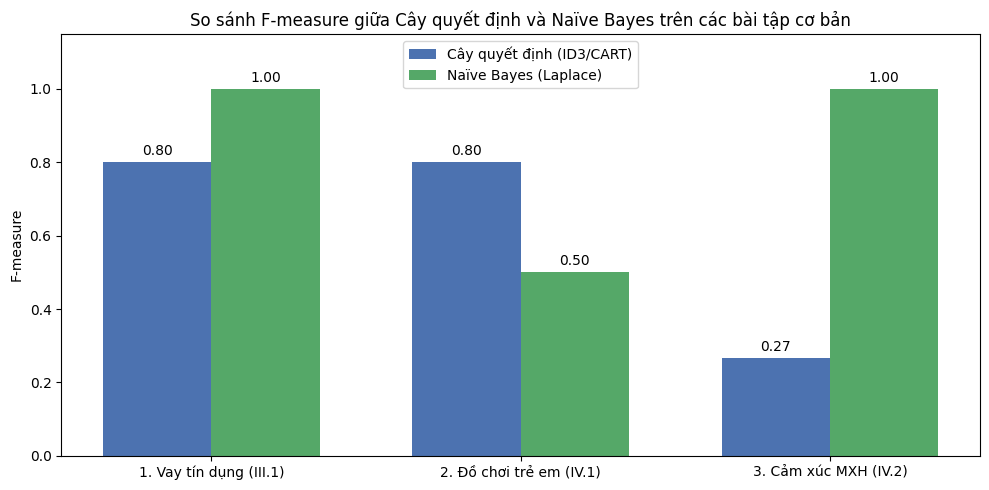

In [5]:
print("Dương Đại Phát - 6451071058")
df_summary = pd.DataFrame(summary_rows)
print("=== BẢNG TỔNG HỢP F-MEASURE CÁC BÀI TẬP CƠ BẢN ===")
print(df_summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
labels_x = df_summary['Bài tập'].unique()
x = np.arange(len(labels_x))
width = 0.35

dt_vals = [df_summary[(df_summary['Bài tập'] == b) & (df_summary['Mô hình'].str.contains('Cây'))]['F-measure'].values[0] for b in labels_x]
nb_vals = [df_summary[(df_summary['Bài tập'] == b) & (df_summary['Mô hình'].str.contains('Naïve'))]['F-measure'].values[0] for b in labels_x]

rects1 = ax.bar(x - width/2, dt_vals, width, label='Cây quyết định (ID3/CART)', color='#4C72B0')
rects2 = ax.bar(x + width/2, nb_vals, width, label='Naïve Bayes (Laplace)', color='#55A868')

ax.set_ylabel('F-measure')
ax.set_title('So sánh F-measure giữa Cây quyết định và Naïve Bayes trên các bài tập cơ bản')
ax.set_xticks(x)
ax.set_xticklabels(labels_x)
ax.set_ylim(0, 1.15)
ax.legend()

for r in rects1 + rects2:
    h = r.get_height()
    ax.annotate(f'{h:.2f}', xy=(r.get_x() + r.get_width() / 2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')

plt.tight_layout()
plt.show()